# Week 04 · Iterative Policy Evaluation — 작은 격자 세계에서의 반복 정책 평가

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week04_dynamic_programming/01_policy_evaluation_gridworld.ipynb)

슬라이드 **"Iterative Policy Evaluation"**, **"Iterative Policy Evaluation (2)"**, **"Evaluating a Random Policy in the Small Gridworld"**,
**"Iterative Policy Evaluation in Small Gridworld"**, **"Iterative Policy Evaluation in Small Gridworld (2)"**를 코드로 재현하고,
**"How to Improve a Policy"**, **"Modified Policy Iteration"**의 핵심 주장("$k=3$이면 충분했다")을 수치로 확인합니다.
슬라이드의 $v_k$ 표($k=0,1,2,3,10,\infty$)와 탐욕 정책(greedy policy) 화살표가 실제 계산에서 그대로 나오는지 비교합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 주 추가 import
from matplotlib.patches import Rectangle

## 1. 작은 격자 세계 (Evaluating a Random Policy in the Small Gridworld)

슬라이드(= Sutton & Barto Example 4.1)의 설정 그대로입니다.

- $4\times 4$ 격자, 상태 번호는 왼쪽 위부터 $0,1,\dots,15$ (행 우선).
- 종단 상태(terminal state) $0$과 $15$ (회색 칸, 형식상 하나의 종단 상태가 두 곳에 그려진 것).
- 행동 $\mathcal{A}=\{\text{up},\text{right},\text{down},\text{left}\}$, 결정적(deterministic) 이동. 격자 밖으로 나가는 행동은 제자리.
- 종단 전까지 모든 전이의 보상 $r=-1$, 할인율 $\gamma=1$ (할인 없는 에피소드형 MDP).
- 평가할 정책: 균등 무작위 정책 $\pi(a|s)=0.25$.

DP는 **모델을 완전히 안다**고 가정합니다. 그래서 먼저 모델을 배열로 만듭니다:
$\mathcal{P}^a_{ss'}$는 `P[a, s, s']`, $\mathcal{R}^a_s$는 `R[a, s]`입니다.
종단 상태는 보상 0으로 자기 자신에게 머무는 흡수 상태(absorbing state)로 두면 $v(\text{terminal})=0$이 자동으로 유지됩니다.

In [2]:
N_ROWS, N_COLS = 4, 4
N_STATES = N_ROWS * N_COLS
TERMINALS = [0, 15]
ACTIONS = ["up", "right", "down", "left"]
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # (d_row, d_col), ACTIONS와 같은 순서
N_ACTIONS = len(ACTIONS)
GAMMA = 1.0


def next_state(s, a):
    """결정적 전이: 상태 s에서 행동 a(인덱스)를 하면 도착하는 상태. 격자 밖이면 제자리."""
    r, c = divmod(s, N_COLS)
    dr, dc = MOVES[a]
    r2, c2 = r + dr, c + dc
    if not (0 <= r2 < N_ROWS and 0 <= c2 < N_COLS):
        return s
    return r2 * N_COLS + c2


# 모델 배열: P[a, s, s'] = P^a_{ss'},  R[a, s] = R^a_s
P = np.zeros((N_ACTIONS, N_STATES, N_STATES))
R = np.zeros((N_ACTIONS, N_STATES))
for s in range(N_STATES):
    for a in range(N_ACTIONS):
        if s in TERMINALS:
            P[a, s, s] = 1.0                      # 흡수 상태, 보상 0
        else:
            P[a, s, next_state(s, a)] = 1.0
            R[a, s] = -1.0

pi_random = np.full((N_STATES, N_ACTIONS), 0.25)   # pi[s, a] = pi(a|s)
print("P shape:", P.shape, "| 각 (a,s) 행의 확률 합이 1인가?", np.allclose(P.sum(-1), 1))
print("예: p(6|5,right) =", P[1, 5, 6], ", p(7|7,right) =", P[1, 7, 7], ", p(10|5,right) =", P[1, 5, 10])

P shape: (4, 16, 16) | 각 (a,s) 행의 확률 합이 1인가? True
예: p(6|5,right) = 1.0 , p(7|7,right) = 1.0 , p(10|5,right) = 0.0


슬라이드 그림처럼 상태 번호와 종단 상태를 그려 봅니다. (아래 그림 함수들은 이후 모든 격자 그림에서 재사용합니다.)

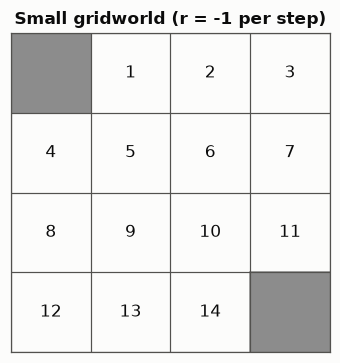

In [3]:
TERMINAL_COLOR = "#8c8c8c"


def setup_grid_axes(ax, title=""):
    """4x4 격자 축: 눈금 없애고 칸 경계선만 그림."""
    ax.set_xlim(-0.5, N_COLS - 0.5)
    ax.set_ylim(N_ROWS - 0.5, -0.5)                  # 행 0이 위쪽
    ax.set_xticks(np.arange(-0.5, N_COLS, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N_ROWS, 1), minor=True)
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.grid(which="minor", color="#52514e", linewidth=0.8)
    ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#52514e")
    ax.set_aspect("equal")
    ax.set_title(title)


def shade_terminals(ax, color=TERMINAL_COLOR):
    for s in TERMINALS:
        r, c = divmod(s, N_COLS)
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color=color, zorder=0))


def draw_values(ax, v, title="", vmax=22.0, decimals=2):
    """상태 가치 표: 크기 |v|를 순차 색상으로, 숫자를 칸에 표시 (어두운 칸은 흰 글씨)."""
    setup_grid_axes(ax, title)
    mag = np.abs(v).reshape(N_ROWS, N_COLS)
    ax.imshow(mag, cmap=SEQ_CMAP, vmin=0, vmax=vmax, extent=(-0.5, N_COLS - 0.5, N_ROWS - 0.5, -0.5), zorder=0)
    shade_terminals(ax, color="#d9d8d2")
    for s in range(N_STATES):
        r, c = divmod(s, N_COLS)
        dark = (s not in TERMINALS) and mag[r, c] / vmax > 0.55
        txt = f"{v[s]:.{decimals}f}" if decimals > 0 else f"{v[s]:.0f}"
        ax.text(c, r, txt, ha="center", va="center", fontsize=8,
                color="white" if dark else "#0b0b0b")


def draw_policy(ax, action_mask, title=""):
    """탐욕 정책: 최대값을 주는 모든 행동을 화살표로 표시 (action_mask[s, a] = True/False)."""
    setup_grid_axes(ax, title)
    shade_terminals(ax)
    for s in range(N_STATES):
        if s in TERMINALS:
            continue
        r, c = divmod(s, N_COLS)
        for a in np.flatnonzero(action_mask[s]):
            dr, dc = MOVES[a]
            ax.annotate("", xy=(c + 0.38 * dc, r + 0.38 * dr), xytext=(c, r),
                        arrowprops=dict(arrowstyle="-|>", color="#0b0b0b", lw=1.1,
                                        shrinkA=0, shrinkB=0, mutation_scale=9))


fig, ax = plt.subplots(figsize=(3.4, 3.4))
setup_grid_axes(ax, "Small gridworld (r = -1 per step)")
shade_terminals(ax)
for s in range(N_STATES):
    if s not in TERMINALS:
        r, c = divmod(s, N_COLS)
        ax.text(c, r, str(s), ha="center", va="center", fontsize=11)
plt.tight_layout(); plt.show()

## 2. 반복 정책 평가 (Iterative Policy Evaluation, Iterative Policy Evaluation (2))

벨만 기대 백업(Bellman expectation backup)을 **동기식(synchronous)**으로, 즉 모든 상태를 이전 $v_k$만 보고 한꺼번에 갱신합니다.

$$v_{k+1}(s) = \sum_{a\in\mathcal{A}} \pi(a|s)\Big[\mathcal{R}^a_s + \gamma \sum_{s'\in\mathcal{S}} \mathcal{P}^a_{ss'}\, v_k(s')\Big]
\qquad\Longleftrightarrow\qquad \mathbf{v}^{k+1} = \mathcal{R}^\pi + \gamma\,\mathcal{P}^\pi \mathbf{v}^{k}$$

아래에서 왼쪽 식(상태별 반복문)과 오른쪽 식(행렬 형태)을 각각 구현하고, 둘이 같은 결과를 내는지 확인합니다.

In [4]:
def evaluation_sweep(v, pi):
    """슬라이드 식 그대로: 모든 s에 대해 v_{k+1}(s) = sum_a pi(a|s) [R^a_s + gamma * sum_s' P^a_ss' v_k(s')]."""
    v_new = np.zeros_like(v)
    for s in range(N_STATES):
        for a in range(N_ACTIONS):
            v_new[s] += pi[s, a] * (R[a, s] + GAMMA * P[a, s] @ v)   # P[a, s] @ v = sum_s' P^a_ss' v(s')
    return v_new                                                     # v는 건드리지 않음 -> 동기식


def policy_model(pi):
    """정책 pi로 평균낸 보상 벡터 R^pi와 전이 행렬 P^pi."""
    R_pi = np.einsum("sa,as->s", pi, R)
    P_pi = np.einsum("sa,ast->st", pi, P)
    return R_pi, P_pi


R_pi, P_pi = policy_model(pi_random)

v_loop = np.zeros(N_STATES)
v_mat = np.zeros(N_STATES)
for k in range(10):
    v_loop = evaluation_sweep(v_loop, pi_random)
    v_mat = R_pi + GAMMA * P_pi @ v_mat
print("반복문 버전과 행렬 버전의 v_10 최대 차이:", np.abs(v_loop - v_mat).max())

반복문 버전과 행렬 버전의 v_10 최대 차이: 0.0


$k\to\infty$의 극한 $v_\pi$는 벨만 기대 방정식 $\mathbf{v}=\mathcal{R}^\pi+\gamma\mathcal{P}^\pi\mathbf{v}$의 해입니다.
$\gamma=1$이므로 종단 상태를 뺀 비종단 상태 부분 $(I-\mathcal{P}^\pi_{NN})\,\mathbf{v}_N = \mathcal{R}^\pi_N$만 풀면 됩니다
(종단 상태를 포함하면 행렬이 특이(singular)해집니다). 이것을 "정답" $v_\pi$로 씁니다.

In [5]:
NONTERM = [s for s in range(N_STATES) if s not in TERMINALS]


def solve_v_exact(pi):
    """선형 방정식을 직접 풀어 v_pi를 구함 (종단 상태 값은 0)."""
    R_pi, P_pi = policy_model(pi)
    A = np.eye(len(NONTERM)) - GAMMA * P_pi[np.ix_(NONTERM, NONTERM)]
    v = np.zeros(N_STATES)
    v[NONTERM] = np.linalg.solve(A, R_pi[NONTERM])
    return v


v_pi = solve_v_exact(pi_random)
print("v_pi (random policy):")
print(v_pi.reshape(4, 4))

v_pi (random policy):
[[  0. -14. -20. -22.]
 [-14. -18. -20. -20.]
 [-20. -20. -18. -14.]
 [-22. -20. -14.   0.]]


## 3. $v_k$와 탐욕 정책의 변화 (Iterative Policy Evaluation in Small Gridworld (1)(2))

슬라이드의 오른쪽 열은 $v_k$에 대한 **탐욕 정책(greedy policy)**입니다.
한 단계 앞을 내다본 행동 가치 $q(s,a) = \mathcal{R}^a_s + \gamma\sum_{s'}\mathcal{P}^a_{ss'}v_k(s')$를 최대로 만드는 행동을
**동점이면 모두** 화살표로 그립니다. 그림의 가치는 소수 둘째 자리까지 적었습니다(슬라이드는 첫째 자리).

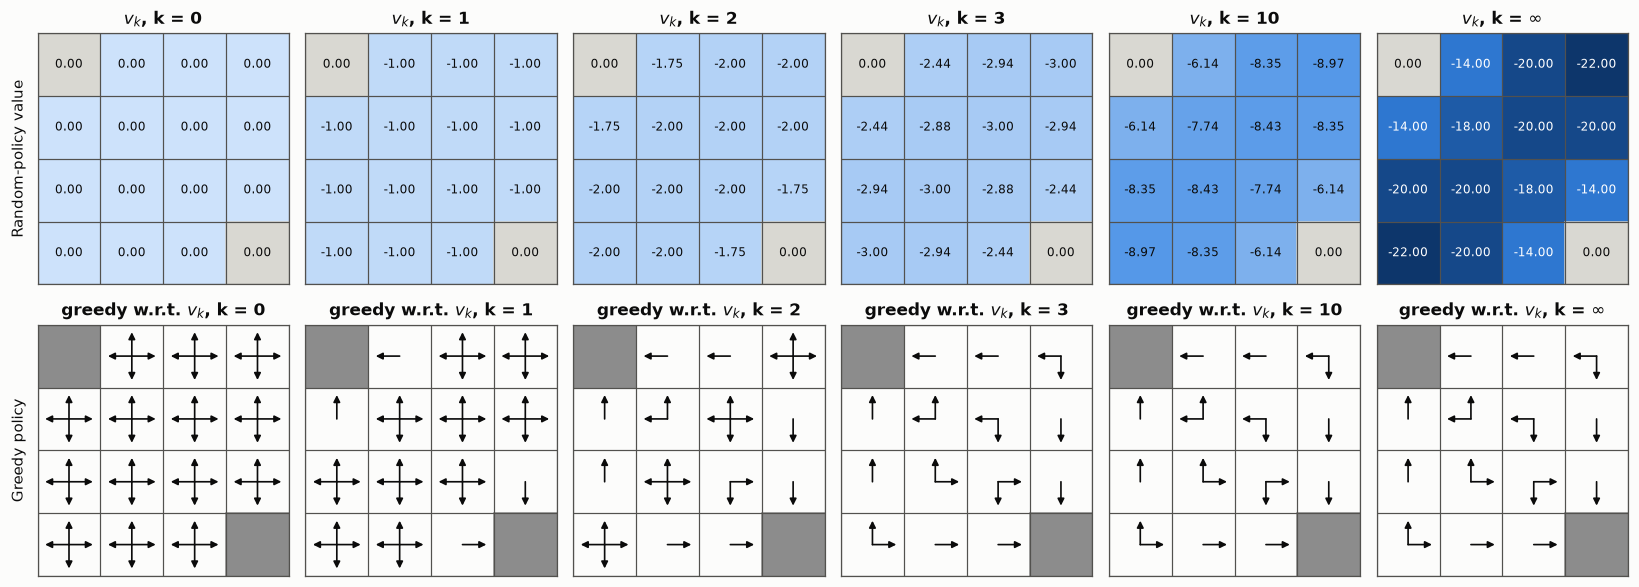

In [6]:
def q_from_v(v):
    """q[s, a] = R^a_s + gamma * sum_s' P^a_ss' v(s')  (한 단계 앞보기)."""
    return R.T + GAMMA * np.einsum("ast,t->sa", P, v)


def greedy_mask(v, tol=1e-9):
    """최대 q를 주는 모든 행동 = True. 종단 상태는 모두 False."""
    q = q_from_v(v)
    mask = q >= q.max(axis=1, keepdims=True) - tol
    mask[TERMINALS] = False
    return mask


# v_k 저장: k = 0, 1, ..., 10 과 "k = inf" (정확한 해)
v_hist = [np.zeros(N_STATES)]
for k in range(10):
    v_hist.append(evaluation_sweep(v_hist[-1], pi_random))
SHOW_K = [0, 1, 2, 3, 10, "inf"]
v_show = {k: (v_pi if k == "inf" else v_hist[k]) for k in SHOW_K}

fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
for j, k in enumerate(SHOW_K):
    label = r"$\infty$" if k == "inf" else str(k)
    draw_values(axes[0, j], v_show[k], title=f"$v_k$, k = {label}")
    draw_policy(axes[1, j], greedy_mask(v_show[k]), title=f"greedy w.r.t. $v_k$, k = {label}")
axes[0, 0].set_ylabel("Random-policy value", fontsize=10)
axes[1, 0].set_ylabel("Greedy policy", fontsize=10)
plt.tight_layout(); plt.show()

### 슬라이드와 비교

슬라이드(tex 204–266행, 454–516행)의 숫자를 그대로 옮겨 적고, 계산값을 소수 첫째 자리로 반올림해 나란히 출력합니다.
슬라이드 표기는 유효숫자 2자리이므로 허용 오차는 $0.05$입니다.

In [7]:
SLIDE_V = {
    0: [[0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]],
    1: [[0.0, -1.0, -1.0, -1.0], [-1.0, -1.0, -1.0, -1.0], [-1.0, -1.0, -1.0, -1.0], [-1.0, -1.0, -1.0, 0.0]],
    2: [[0.0, -1.7, -2.0, -2.0], [-1.7, -2.0, -2.0, -2.0], [-2.0, -2.0, -2.0, -1.7], [-2.0, -2.0, -1.7, 0.0]],
    3: [[0.0, -2.4, -2.9, -3.0], [-2.4, -2.9, -3.0, -2.9], [-2.9, -3.0, -2.9, -2.4], [-3.0, -2.9, -2.4, 0.0]],
    10: [[0.0, -6.1, -8.4, -9.0], [-6.1, -7.7, -8.4, -8.4], [-8.4, -8.4, -7.7, -6.1], [-9.0, -8.4, -6.1, 0.0]],
    "inf": [[0.0, -14., -20., -22.], [-14., -18., -20., -20.], [-20., -20., -18., -14.], [-22., -20., -14., 0.0]],
}

for k in SHOW_K:
    slide = np.array(SLIDE_V[k])
    ours = v_show[k].reshape(4, 4)
    print(f"--- k = {k} ---   (왼쪽: 계산값 소수 둘째 자리까지 | 오른쪽: 슬라이드)")
    for r in range(4):
        left = " ".join(f"{x:6.2f}" for x in ours[r])
        right = " ".join(f"{x:5.1f}" for x in slide[r])
        print(f"  {left}   |  {right}")
    assert np.all(np.abs(ours - slide) <= 0.05 + 1e-9), f"k={k}: slide mismatch"
print("\n모든 v_k 표가 슬라이드와 일치합니다 (|차이| <= 0.05).")

--- k = 0 ---   (왼쪽: 계산값 소수 둘째 자리까지 | 오른쪽: 슬라이드)
    0.00   0.00   0.00   0.00   |    0.0   0.0   0.0   0.0
    0.00   0.00   0.00   0.00   |    0.0   0.0   0.0   0.0
    0.00   0.00   0.00   0.00   |    0.0   0.0   0.0   0.0
    0.00   0.00   0.00   0.00   |    0.0   0.0   0.0   0.0
--- k = 1 ---   (왼쪽: 계산값 소수 둘째 자리까지 | 오른쪽: 슬라이드)
    0.00  -1.00  -1.00  -1.00   |    0.0  -1.0  -1.0  -1.0
   -1.00  -1.00  -1.00  -1.00   |   -1.0  -1.0  -1.0  -1.0
   -1.00  -1.00  -1.00  -1.00   |   -1.0  -1.0  -1.0  -1.0
   -1.00  -1.00  -1.00   0.00   |   -1.0  -1.0  -1.0   0.0
--- k = 2 ---   (왼쪽: 계산값 소수 둘째 자리까지 | 오른쪽: 슬라이드)
    0.00  -1.75  -2.00  -2.00   |    0.0  -1.7  -2.0  -2.0
   -1.75  -2.00  -2.00  -2.00   |   -1.7  -2.0  -2.0  -2.0
   -2.00  -2.00  -2.00  -1.75   |   -2.0  -2.0  -2.0  -1.7
   -2.00  -2.00  -1.75   0.00   |   -2.0  -2.0  -1.7   0.0
--- k = 3 ---   (왼쪽: 계산값 소수 둘째 자리까지 | 오른쪽: 슬라이드)
    0.00  -2.44  -2.94  -3.00   |    0.0  -2.4  -2.9  -3.0
   -2.44  -2.88  -3.00  -2.94   |   -

**주의 — $k=2$의 $-1.7$:** 정확한 값은 $-1.75$로 반올림 경계에 걸립니다. 슬라이드와 교재(Figure 4.1)는 $-1.7$로,
파이썬 `round`/`format`은 $-1.8$로 표기합니다. 둘 다 $-1.75$를 두 자리로 적은 것이므로 오류가 아닙니다.
한 번의 동기식 스윕 후 모든 값이 $-1$이고, 상태 1은 행동 4개 중 하나(left)만 종단 상태로 가므로
$v_2(1) = 0.25\,(-1+0) + 0.75\,(-1-1) = -1.75$입니다.

이번에는 **탐욕 정책 화살표**를 비교합니다. 슬라이드 그림의 화살표를 칸마다 문자열로 옮겼습니다
(U=up, R=right, D=down, L=left, T=종단).

In [8]:
SLIDE_POLICY = {
    0: ["T UDLR UDLR UDLR", "UDLR UDLR UDLR UDLR", "UDLR UDLR UDLR UDLR", "UDLR UDLR UDLR T"],
    1: ["T L UDLR UDLR", "U UDLR UDLR UDLR", "UDLR UDLR UDLR D", "UDLR UDLR R T"],
    2: ["T L L UDLR", "U UL UDLR D", "U UDLR DR D", "UDLR R R T"],
    3: ["T L L DL", "U UL DL D", "U UR DR D", "UR R R T"],
}
SLIDE_POLICY[10] = SLIDE_POLICY[3]       # 슬라이드: k = 3, 10, inf 모두 같은 (최적) 정책
SLIDE_POLICY["inf"] = SLIDE_POLICY[3]
LETTER = {"U": 0, "R": 1, "D": 2, "L": 3}


def mask_from_strings(rows):
    mask = np.zeros((N_STATES, N_ACTIONS), dtype=bool)
    cells = " ".join(rows).split()
    for s, cell in enumerate(cells):
        if cell != "T":
            for ch in cell:
                mask[s, LETTER[ch]] = True
    return mask


def mask_to_strings(mask):
    cells = []
    for s in range(N_STATES):
        cells.append("T" if s in TERMINALS else "".join(ch for ch in "UDLR" if mask[s, LETTER[ch]]))
    return [" ".join(f"{c:>4}" for c in cells[r * 4:(r + 1) * 4]) for r in range(4)]


for k in SHOW_K:
    ours = greedy_mask(v_show[k])
    same = np.array_equal(ours, mask_from_strings(SLIDE_POLICY[k]))
    print(f"k = {k:>3}: 계산한 탐욕 정책 == 슬라이드 화살표?  {same}")
    assert same
print("\nk = 3 탐욕 정책 (계산값):")
print("\n".join(mask_to_strings(greedy_mask(v_show[3]))))

k =   0: 계산한 탐욕 정책 == 슬라이드 화살표?  True
k =   1: 계산한 탐욕 정책 == 슬라이드 화살표?  True
k =   2: 계산한 탐욕 정책 == 슬라이드 화살표?  True
k =   3: 계산한 탐욕 정책 == 슬라이드 화살표?  True
k =  10: 계산한 탐욕 정책 == 슬라이드 화살표?  True
k = inf: 계산한 탐욕 정책 == 슬라이드 화살표?  True

k = 3 탐욕 정책 (계산값):
   T    L    L   DL
   U   UL   DL    D
   U   UR   DR    D
  UR    R    R    T


여섯 개 $v_k$ 표와 여섯 개 탐욕 정책이 모두 슬라이드와 정확히 같습니다.
값은 $k$가 커질수록 종단 상태에서 멀리 떨어진 칸일수록 더 음수가 되어, $v_\pi(s)$가 "무작위로 걸을 때 종단까지 걸리는 평균 걸음 수의 음수"가 됩니다.
반면 탐욕 정책은 $k=3$부터 이미 더 이상 바뀌지 않습니다.

## 4. 값은 천천히, 정책은 빨리 수렴 (How to Improve a Policy, Modified Policy Iteration)

슬라이드의 두 주장을 확인합니다.

1. **"In the small gridworld, the improved policy was optimal, $\pi' = \pi^*$."** — 무작위 정책의 $v_\pi$에 대한 탐욕 정책은 이미 최적입니다.
2. **"In the small gridworld, $k = 3$ was sufficient to find the optimal policy."** — 정책 평가를 끝까지 수렴시키지 않아도 됩니다.

각 $k$에 대해 탐욕 정책 $\pi'_k=\text{greedy}(v_k)$ (동점 행동은 균등 확률)를 만들고, 그 **정책의 실제 가치** $v_{\pi'_k}$를 정확히 계산해
최적 가치 $v_*(s) = -(\text{가장 가까운 종단까지의 거리})$와 비교합니다.

In [9]:
def mask_to_policy(mask):
    """탐욕 행동 집합 -> 동점 행동에 균등 확률을 준 확률적 정책 pi[s, a]."""
    pi = mask.astype(float)
    pi[TERMINALS] = 1.0                         # 종단 상태: 아무 행동이나 (값에 영향 없음)
    return pi / pi.sum(axis=1, keepdims=True)


# 최적 가치: 가장 가까운 종단 상태까지의 맨해튼 거리 (장애물이 없으므로)
v_star = np.array([-min(abs(r - 0) + abs(c - 0), abs(r - 3) + abs(c - 3))
                   for r, c in (divmod(s, 4) for s in range(N_STATES))], dtype=float)

v_long = [np.zeros(N_STATES)]
for k in range(400):
    v_long.append(evaluation_sweep(v_long[-1], pi_random))

print(" k | max_s |v_k - v_pi| | greedy(v_k)의 가치가 v*인가? | max_s (v* - v_greedy)")
for k in [0, 1, 2, 3, 4, 10, 100]:
    v_g = solve_v_exact(mask_to_policy(greedy_mask(v_long[k])))
    gap = np.max(v_star - v_g)
    print(f"{k:>3}| {np.abs(v_long[k] - v_pi).max():20.4f} | {str(gap < 1e-9):>27} | {gap:8.3f}")
v_g_inf = solve_v_exact(mask_to_policy(greedy_mask(v_pi)))
print(f"inf| {0:20.4f} | {str(np.max(v_star - v_g_inf) < 1e-9):>27} | {np.max(v_star - v_g_inf):8.3f}")
assert np.allclose(v_g_inf, v_star)                                          # pi' = pi*
assert np.allclose(solve_v_exact(mask_to_policy(greedy_mask(v_long[3]))), v_star)   # k = 3이면 충분
assert not np.allclose(solve_v_exact(mask_to_policy(greedy_mask(v_long[2]))), v_star)

 k | max_s |v_k - v_pi| | greedy(v_k)의 가치가 v*인가? | max_s (v* - v_greedy)
  0|              22.0000 |                       False |   19.000
  1|              21.0000 |                       False |    6.000
  2|              20.0000 |                       False |    1.000
  3|              19.0000 |                        True |    0.000
  4|              18.0313 |                        True |    0.000
 10|              13.0327 |                        True |    0.000
100|               0.0952 |                        True |    0.000
inf|               0.0000 |                        True |    0.000


오차 $\|v_k - v_\pi\|_\infty$를 로그 축으로 그려 보면 **기하급수적(geometric)**으로 줄어듭니다.
$\gamma=1$인데도 수렴하는 이유는 종단 상태 때문에 비종단 부분 전이 행렬 $\mathcal{P}^\pi_{NN}$의 스펙트럼 반경(spectral radius)
$\rho<1$이기 때문이며, 오차는 대략 $\rho^k$ 비율로 줄어듭니다 (Contraction Mapping 절에서 $\gamma<1$일 때의 일반 논증을 다룹니다).

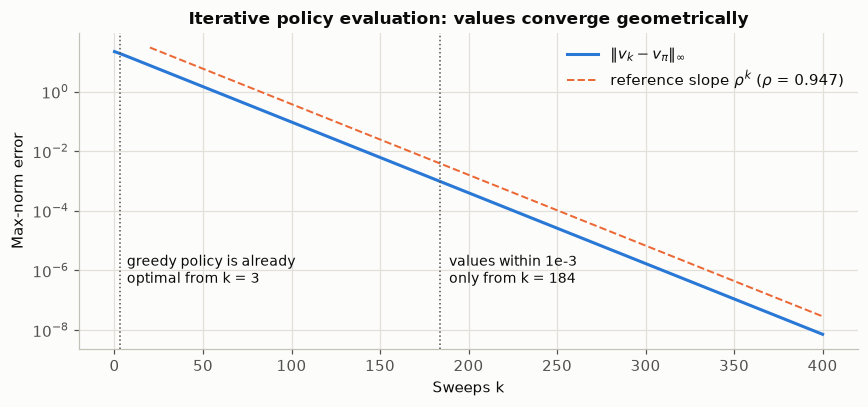

spectral radius rho = 0.9468,  오차 1e-3 도달: k = 184 스윕


In [10]:
errors = np.array([np.abs(v - v_pi).max() for v in v_long])
rho = np.max(np.abs(np.linalg.eigvals(P_pi[np.ix_(NONTERM, NONTERM)])))
ks = np.arange(len(errors))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogy(ks, errors, color=PALETTE[0], label=r"$\|v_k - v_\pi\|_\infty$")
ax.semilogy(ks[20:], 4 * errors[20] * rho ** (ks[20:] - 20), "--", color=PALETTE[1], lw=1.3,
            label=rf"reference slope $\rho^k$ ($\rho$ = {rho:.3f})")
ax.axvline(3, color="#52514e", lw=1, ls=":")
ax.text(7, 1e-6, "greedy policy is already\noptimal from k = 3", fontsize=9, va="center")
k_tol = int(np.argmax(errors < 1e-3))
ax.axvline(k_tol, color="#52514e", lw=1, ls=":")
ax.text(k_tol + 5, 1e-6, f"values within 1e-3\nonly from k = {k_tol}", fontsize=9, va="center")
ax.set_xlabel("Sweeps k"); ax.set_ylabel("Max-norm error")
ax.set_title("Iterative policy evaluation: values converge geometrically")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
print(f"spectral radius rho = {rho:.4f},  오차 1e-3 도달: k = {k_tol} 스윕")

값이 $10^{-3}$ 이내로 수렴하려면 약 180번의 스윕이 필요하지만, 탐욕 정책은 3번째 스윕 이후 바뀌지 않습니다.
그래서 정책 반복(policy iteration)에서 평가 단계를 일찍 끊어도 되며(**modified policy iteration**), 극단적으로 $k=1$에서 끊고
매번 정책을 개선하면 **가치 반복(value iteration)**이 됩니다. 이 비교는 `02_policy_iteration_jacks_car_rental.ipynb`에서
Jack's Car Rental로 다시 해 봅니다.

## 직접 해보기

1. **할인율**: `GAMMA = 0.9`로 바꾸고 다시 실행해 보세요. $v_\pi$의 절댓값이 크게 줄고(멀리 있는 $-1$들이 할인됨) 수렴도 빨라집니다.
   (슬라이드 비교 `assert`는 $\gamma=1$ 전용이므로 실패하는 것이 정상입니다.) 탐욕 정책은 달라지나요?
2. **교재 연습문제 4.2**: 상태 13 아래에 새 상태 15를 추가하고(행동 left, up, right, down이 각각 12, 13, 14, 15로 이동)
   무작위 정책의 $v_\pi(15)$를 계산해 보세요. 교재 답: $-20$. 상태 13의 down이 새 상태로 가도록 바꾸면 값이 달라질까요?
3. **정책 바꾸기**: `pi_random` 대신 "항상 left"처럼 종단에 도달하지 못하는 상태가 있는 정책을 넣으면 `solve_v_exact`가 실패합니다.
   왜 그런지($\gamma=1$에서 $I-\mathcal{P}^\pi_{NN}$이 특이해지는 이유) 생각해 보세요.
4. **반올림된 표로 탐욕 정책 그리기**: `draw_policy(ax, greedy_mask(np.round(v_show[3], 1)))`처럼 슬라이드에 적힌 반올림 값으로
   탐욕 정책을 구해 보세요. 상태 9의 화살표가 슬라이드와 달라집니다. 정확한 값($v_3(5)=-2.875$, $v_3(8)=-2.9375$)과 비교해 이유를 설명해 보세요.